# 04 — Detecting the poisoned training samples

**The defender's situation.** The defender received a training set (23,880 images) and trained the model on it, without knowing that 24 Stop images carry a trigger and were relabelled as Speed limit 80. They have three things: this training set with its labels, the trained model, and the small clean validation set. They do **not** know which samples are poisoned, nor which class is the target.

The three detection methods below look at what the model has learned: the activations of its **last hidden layer** (256 units, `model.features()`). The idea (Chen et al., 2018) is that a poisoned image labelled Speed limit 80 is still a Stop sign: the model must use a different internal reason (the trigger) to put it in that class, so its activations sit apart from those of genuine Speed limit 80 signs.

**Golden rule.** The detection methods never use the true poison indices, neither to decide nor to choose a parameter. All parameters are fixed beforehand in `configs/base.yaml` (section `detection`) and justified below. The poison record is opened only at the end, to *evaluate* a detection that is already finished.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import numpy as np
import pandas as pd

from src.config import load_config, resolve_path
from src.data import GTSRB_CLASS_NAMES, load_gtsrb, load_train_groups, train_val_split
from src.detection import run_detection
from src.experiment import compare_art_cluster_analyses, detection_rows, load_poisoned_run, score_detection
from src.plots import plot_detection_errors, plot_detection_summary, plot_flagged_per_class, plot_target_class_pca
from src.utils import save_env_info, save_json, set_seed

cfg = load_config()
set_seed(cfg["seed"])
save_env_info(resolve_path(cfg, "env_info"))
figures_dir, metrics_dir = resolve_path(cfg, "figures_dir"), resolve_path(cfg, "metrics_dir")
source, target = cfg["backdoor"]["source_class"], cfg["backdoor"]["target_class"]
num_classes = cfg["data"]["num_classes"]
METHODS = {
    "clustering": "Activation clustering (ours)",
    "art": "ART ActivationDefence",
    "centroid": "Distance to centroid",
    "calibrated": "Calibrated distance (clean val)",
}
A_PRIORI = ("clustering", "art", "centroid")

INFO art.config: set ART_DATA_PATH to /home/mdev/.art/data


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/env_info.json


## 1. Parameters, fixed before looking at any result

| method | parameters | why |
|---|---|---|
| Activation clustering (ours) | per class: PCA to 10 dims, KMeans with 2 clusters, flag the smaller cluster if it holds less than 35% of the class | the values of Chen et al. (2018), also ART's defaults: a class without poison should split into two comparable halves, a poisoned class into a big clean cluster and a small poisoned one |
| ART ActivationDefence | same clustering, `cluster_analysis="relative-size"` (threshold 0.35) | the paper's criterion and the same rule as our version, so the two can be compared; `"smaller"` would flag the smaller cluster of *every* class by construction |
| Distance to centroid | per class: PCA to 10 dims, z-score of the distance to the class centroid, flag z > 3 | classic outlier rule: for a normal distribution about 0.13% of points lie above 3 standard deviations |

ART's `ActivationDefence` takes the activations of the **last** layer of the classifier. For our model that is the 43-unit output layer, not the 256-unit hidden layer of the paper. `src/detection.py` makes it read the hidden layer (`fc`), and a test checks that these activations equal `model.features()`.

Sections 3 to 6 report these three **a priori** methods. A fourth method, calibrated on the clean validation set, was designed after seeing why they fail; it is presented separately in section 8, with its own parameters fixed before it was run.

## 2. Data: the training set the defender received

The clean training split is rebuilt as in the previous notebooks, then the saved poison record is applied to recreate exactly the poisoned training set that `poisoned_r05` was trained on. In a real situation the defender would simply receive this set; here the record is only used to rebuild it and, at the end, to score the detection. The detection functions receive `x_defender, y_defender` and the model, nothing else.

In [2]:
x_full, y_full, _, _ = load_gtsrb(cfg)
x_train, y_train, x_val, y_val = train_val_split(x_full, y_full, load_train_groups(cfg), cfg["data"]["val_ratio"], cfg["seed"])
main_name, model, x_defender, y_defender, record, _ = load_poisoned_run(x_train, y_train, cfg, cfg["backdoor"]["poison_rate"])
print(f"{main_name}: {len(y_defender)} training images, model loaded (no retraining)")

INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


poisoned_r05: 23880 training images, model loaded (no retraining)


## 3. Running the detection methods

`run_detection` extracts the activations of the last hidden layer for all training images and runs the methods. It receives only the training images, their labels, the model and the clean validation set (used by Method 4 only). The counts below are the three a priori methods.

In [3]:
detection = run_detection(model, x_defender, y_defender, x_val, y_val, cfg)
pd.Series({METHODS[m]: int(detection["suspects"][m].sum()) for m in A_PRIORI}).to_frame("flagged samples")

INFO art.estimators.classification.pytorch: Inferred 4 hidden layers on PyTorch classifier.


,flagged samples
Activation clustering (ours),1142
ART ActivationDefence,1013
Distance to centroid,260


## 4. Why it can work: the target class seen by the model

From here on we use the poison record to **evaluate**. The figure projects to 2D the activations of all training samples labelled Speed limit 80 (1,140 genuine signs plus the 24 poisoned Stop images). Blue: clean, red: poisoned (ground truth, shown for explanation only). The circles are the samples flagged by each method.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/pca_target_class.png


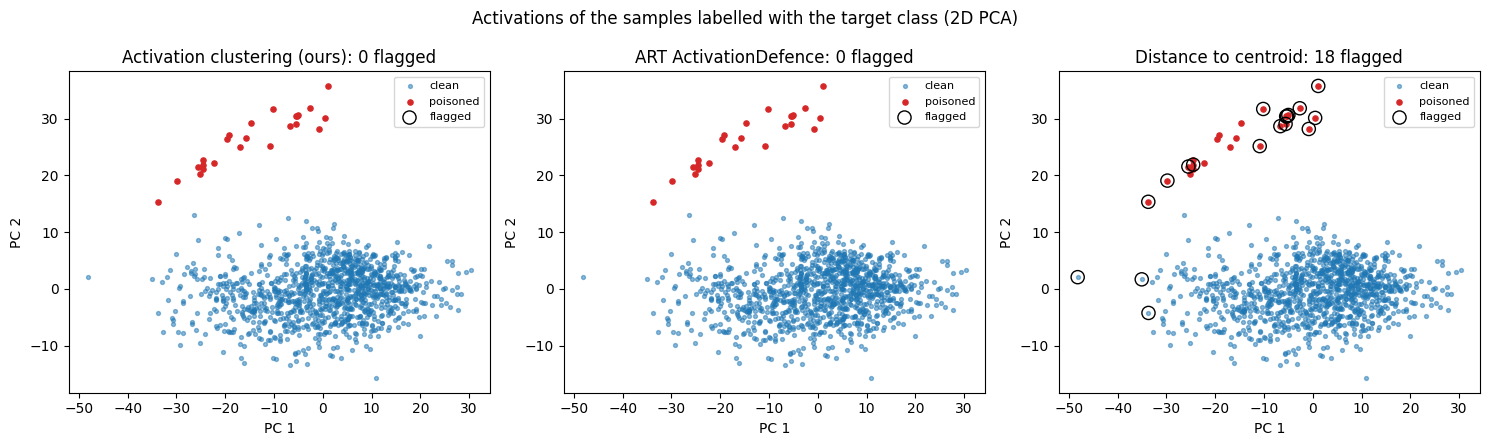

In [4]:
poison_idx = np.array(record["indices"])
is_poison = np.zeros(len(y_defender), dtype=bool)
is_poison[poison_idx] = True
in_target = y_defender == target
plot_target_class_pca(
    detection["activations"][in_target], is_poison[in_target],
    {METHODS[m]: detection["suspects"][m][in_target] for m in A_PRIORI},
    path=figures_dir / "pca_target_class.png",
);

## 5. Scores

In simple words:
- a **true positive** (TP) is a poisoned image that was flagged; a **false positive** (FP) is a clean image wrongly flagged; a **false negative** (FN) is a poisoned image that was missed;
- **precision** = TP / flagged: when the method raises an alarm, how often is it right? Low precision means many clean images would be thrown away;
- **recall** = TP / poisoned: which share of the poison was found? Low recall means poison stays in the training set;
- **F1** combines both (harmonic mean): it is high only if both are high.

For remediation, recall matters most (every missed image can keep the backdoor alive), but a very low precision costs clean training data.

In [5]:
results = {main_name: score_detection(main_name, detection["suspects"], y_defender, record, cfg)}
summary = detection_rows(main_name, results[main_name])


def score_frame(rows: list[dict], methods) -> pd.DataFrame:
    frame = pd.DataFrame([r for r in rows if r["method"] in methods])
    return frame.assign(method=frame["method"].map(METHODS)).set_index("method").drop(columns="run_name").round(3)


score_frame(summary, A_PRIORI)

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_clustering_poisoned_r05.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_art_poisoned_r05.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_centroid_poisoned_r05.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_calibrated_poisoned_r05.json


,n_flagged,tp,fp,fn,precision,recall,f1,flagged_in_target_class
method,,,,,,,,
Activation clustering (ours),1142,0,1142,24,0.000,0.000,0.000,0
ART ActivationDefence,1013,0,1013,24,0.000,0.000,0.000,0
Distance to centroid,260,15,245,9,0.058,0.625,0.106,18


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/detection_summary.png


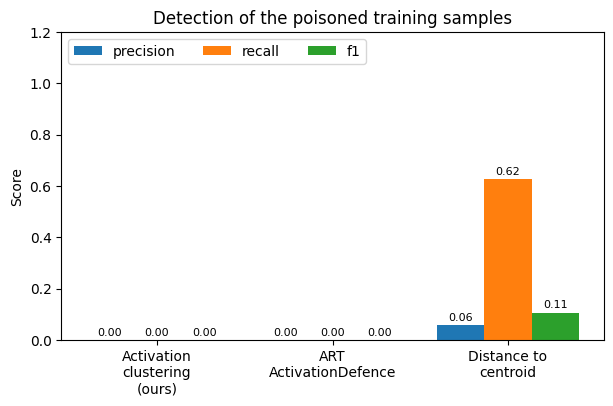

In [6]:
plot_detection_summary(
    [{"method": METHODS[m], **results[main_name][m]} for m in A_PRIORI], figures_dir / "detection_summary.png"
);

## 6. Where do the false positives come from, and what is missed?

Flagged samples per training label: a method that works only flags samples in the target class (5).

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/flagged_per_class.png


,classes with flags,flags outside the target class
Activation clustering (ours),10,1142
ART ActivationDefence,9,1013
Distance to centroid,38,242


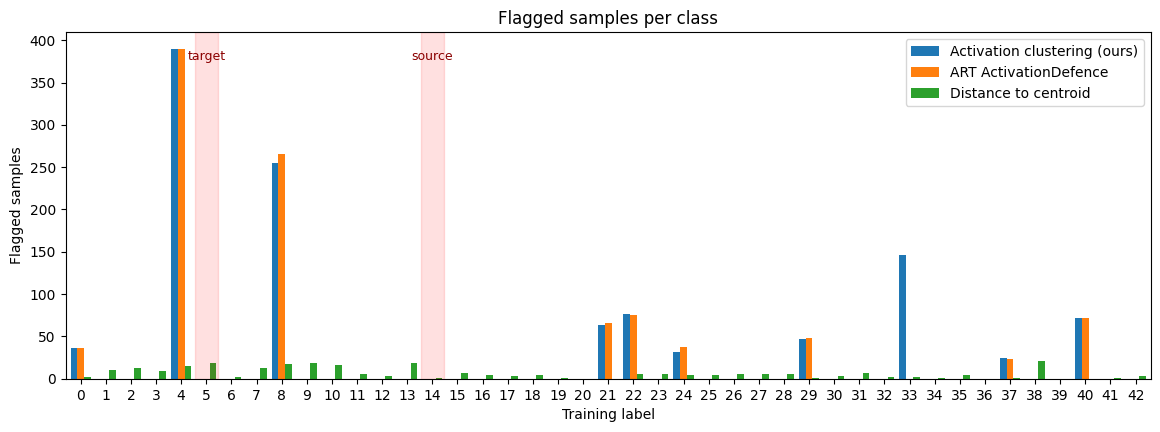

In [7]:
plot_flagged_per_class(
    {METHODS[m]: results[main_name][m]["flagged_per_class"] for m in A_PRIORI}, num_classes,
    highlight={source: "source", target: "target"}, path=figures_dir / "flagged_per_class.png",
);
pd.DataFrame(
    {METHODS[m]: {"classes with flags": len(r["flagged_per_class"]),
                  "flags outside the target class": r["n_flagged"] - r["flagged_in_target_class"]}
     for m, r in results[main_name].items() if m in A_PRIORI}
).T

Our clustering method splits every class into two clusters. The table lists the classes where the smaller cluster fell under the 35% threshold, plus the target class whatever its result, with the silhouette score (how well separated the two clusters are, from -1 to 1).

In [8]:
info = detection["clustering_info"]
pd.DataFrame(
    [{"class": f"{c}: {GTSRB_CLASS_NAMES[c]}", **i}
     for c, i in info.items() if i["flagged"] or c == target]
).round(3)

,class,cluster_sizes,smaller_share,silhouette,flagged
0,0: Speed limit (20km/h),"[36, 84]",0.300,0.457,True
1,4: Speed limit (70km/h),"[810, 390]",0.325,0.380,True
2,5: Speed limit (80km/h),"[443, 721]",0.381,0.313,False
3,8: Speed limit (120km/h),"[615, 255]",0.293,0.353,True
4,21: Double curve,"[146, 64]",0.305,0.386,True
5,22: Bumpy road,"[164, 76]",0.317,0.344,True
6,24: Road narrows on the right,"[118, 32]",0.213,0.385,True
7,29: Bicycles crossing,"[103, 47]",0.313,0.452,True
8,33: Turn right ahead,"[274, 146]",0.348,0.408,True
9,37: Go straight or left,"[96, 24]",0.200,0.398,True


A few errors of each method: false positives (clean images flagged) and false negatives (poisoned images missed), with their training label.

/home/mdev/Dev/school/SD/gtsrb-data-poisoning/src/plots.py:324: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/detection_errors.png


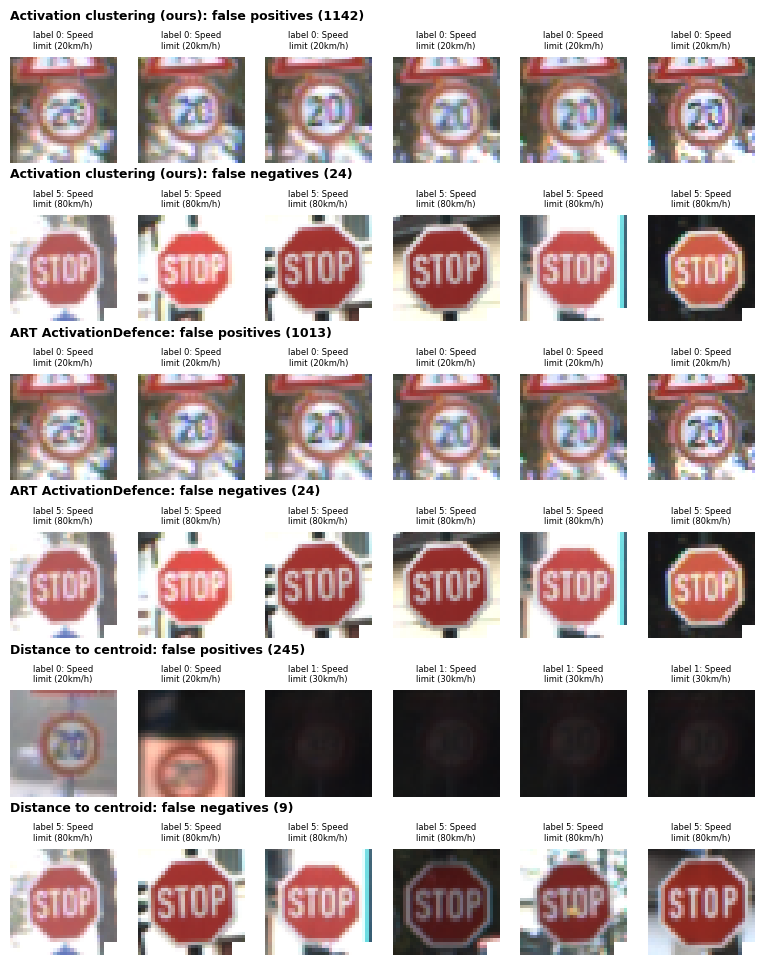

In [9]:
plot_detection_errors(
    x_defender, y_defender,
    {METHODS[m]: (results[main_name][m]["false_positive_indices"], results[main_name][m]["false_negative_indices"])
     for m in A_PRIORI},
    GTSRB_CLASS_NAMES, n=6, path=figures_dir / "detection_errors.png",
);

## 7. Why the a priori methods failed

- **Dilution.** The poisoning rate is defined on the source class (5% of the Stop images), but detection looks at the samples *labelled* with the target class. There the 24 poisoned images are only 2.1% of the class (24 out of 1,164); at 10%, 4.0% (48 out of 1,188).
- **2-means cuts the clean mass.** The PCA figure shows the poisoned images as a separate group, yet KMeans with two clusters prefers to cut the large, elongated clean group in two: that reduces its error more than isolating 24 points. The smaller cluster then holds 38% of the class, above the 35% threshold, and the target class is not flagged.
- **Clean classes split naturally.** About ten clean classes divide into unequal parts (lighting, distance, sign variants) and fall under the 35% threshold: all their flags are false positives.
- **Contaminated statistics.** The distance-to-centroid rule computes the centroid, the mean and the spread of distances on the training data, which contains the poison. The poisoned images pull these statistics towards themselves; at 10% they hide better (median z-score 3.4 at 5%, 2.4 at 10%). And distances have a heavy tail, so z > 3 flags about 1% of every class instead of the 0.13% a normal distribution would give.

## 8. Method 4: distance to centroid, calibrated on the trusted validation set

The threat model says the defender trusts the clean validation split. Method 4 uses it as the reference for "normal", which removes the contamination problem without using the ground truth:

- for each class, the **centroid of the clean validation activations** of that class;
- distance of each image to that centroid, **Euclidean in the full 256-dimensional hidden layer** (no PCA: a PCA fitted on clean images keeps only the directions in which clean images vary, and could erase the offset the trigger creates in another direction; it would also be estimated from as few as 30 images);
- distances are divided by the **median distance of the clean validation images of the class**, so a score of 1 means "as far as a typical clean image";
- the threshold is the **99th percentile of these scores pooled over the 2,760 validation images**; every training image above it is flagged. Pooling is needed because the smallest validation classes have only 30 images: a per-class 99th percentile would just be the class maximum.

**Parameters** (`detection.calibrated` in the config): full space, percentile 99. They were fixed after seeing why the a priori methods fail, but **before running this method**, and are not changed after. With percentile 99 we expect about **1% of clean images** to be flagged, if they behave like the validation images. Training images were seen during training, so their activations may sit closer to the centroids and the measured rate may be lower: the next cell measures it.

In [10]:
calibrated = results[main_name]["calibrated"]
n_clean_train = len(y_defender) - len(record["indices"])
print(f"threshold (99th percentile of pooled clean validation scores): {detection['calibrated_threshold']:.3f}")
print(f"clean training images flagged: {calibrated['fp']} / {n_clean_train} = {calibrated['fp'] / n_clean_train:.2%} (expected about 1%)")
score_frame(summary, METHODS)

threshold (99th percentile of pooled clean validation scores): 2.393
clean training images flagged: 2958 / 23856 = 12.40% (expected about 1%)


,n_flagged,tp,fp,fn,precision,recall,f1,flagged_in_target_class
method,,,,,,,,
Activation clustering (ours),1142,0,1142,24,0.000,0.000,0.000,0
ART ActivationDefence,1013,0,1013,24,0.000,0.000,0.000,0
Distance to centroid,260,15,245,9,0.058,0.625,0.106,18
Calibrated distance (clean val),2965,7,2958,17,0.002,0.292,0.005,7


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/pca_target_class_all_methods.png


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/detection_summary_all_methods.png


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/flagged_per_class_all_methods.png


/home/mdev/Dev/school/SD/gtsrb-data-poisoning/src/plots.py:324: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/detection_errors_all_methods.png


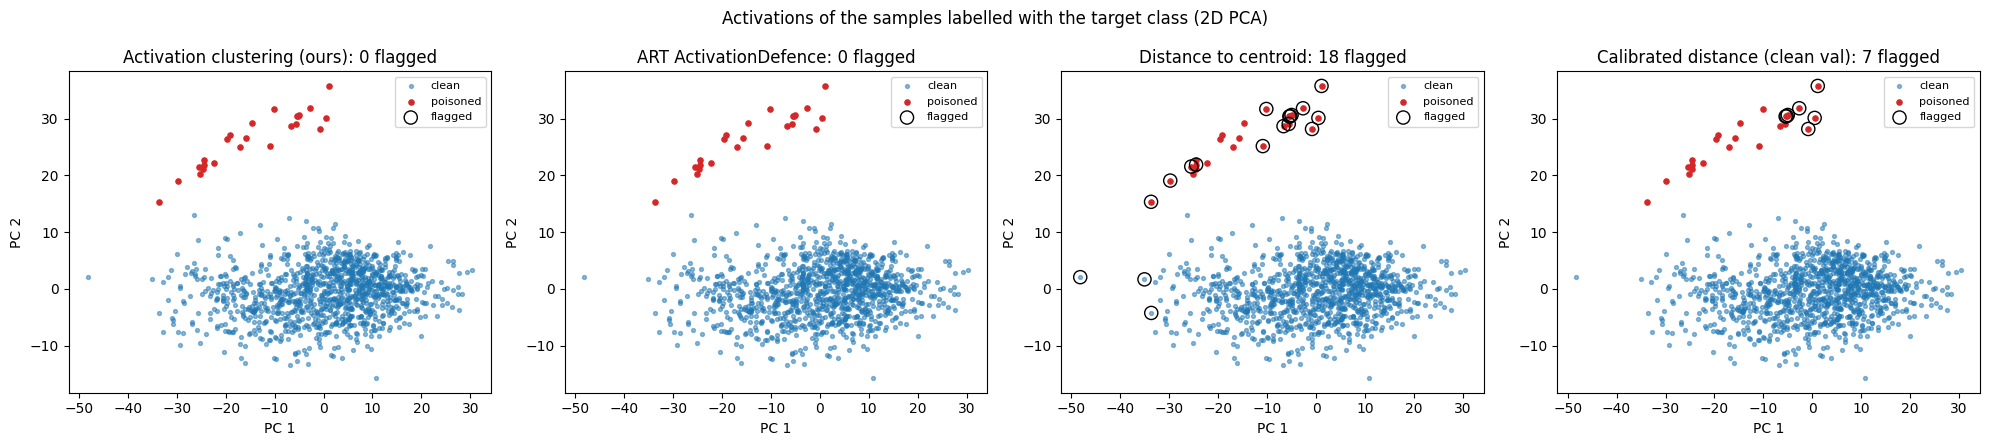

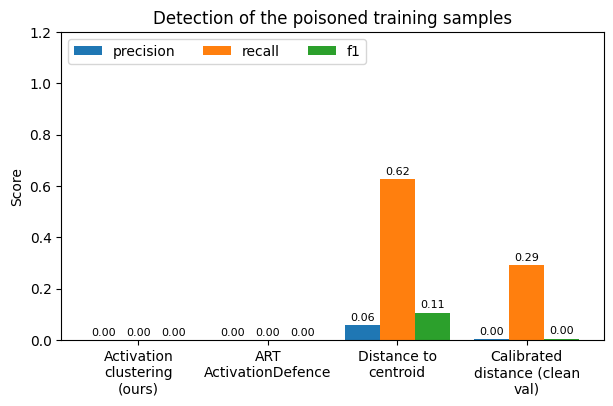

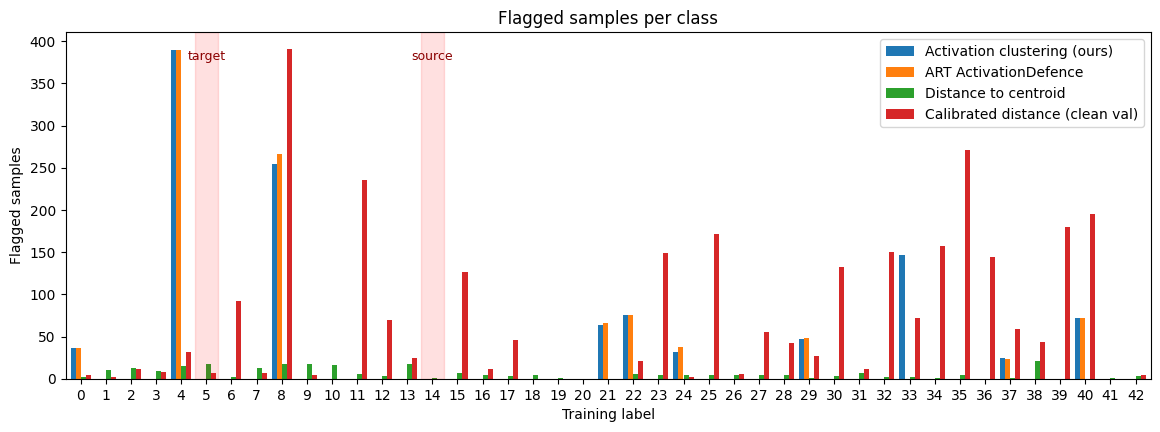

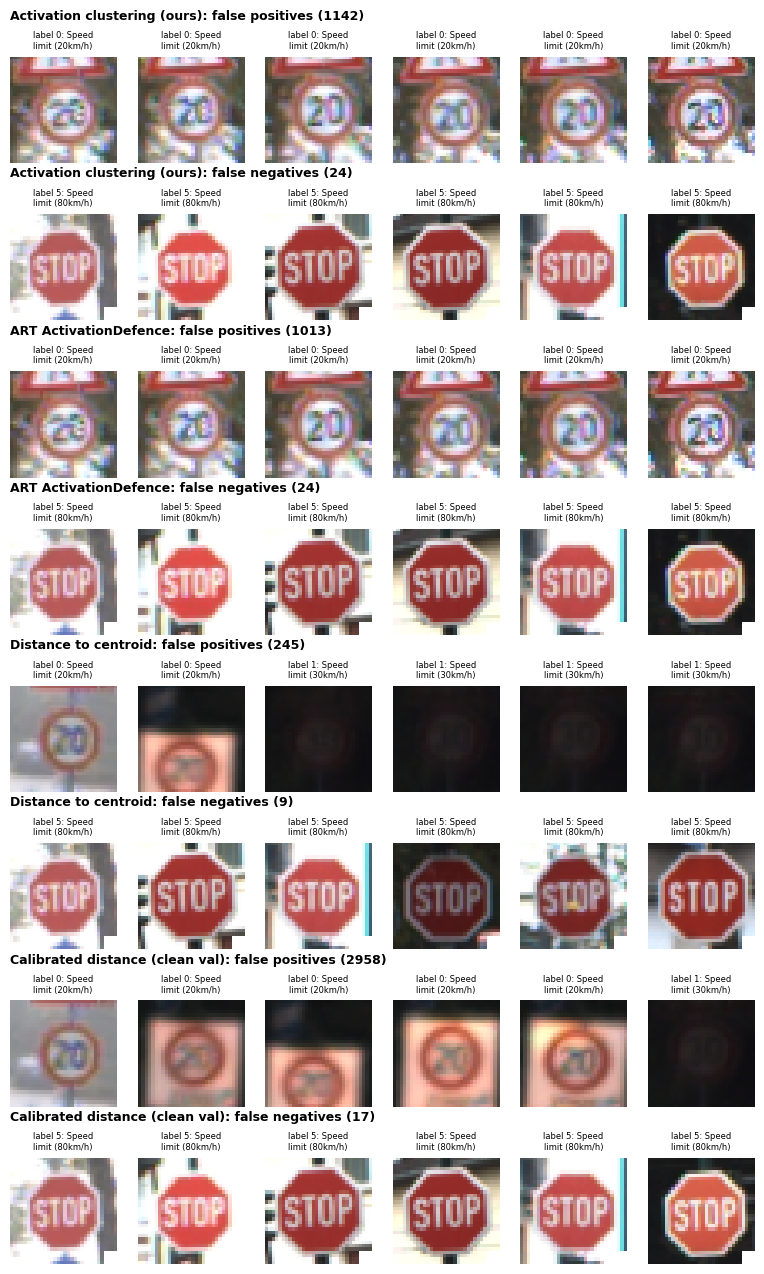

In [11]:
plot_target_class_pca(
    detection["activations"][in_target], is_poison[in_target],
    {METHODS[m]: s[in_target] for m, s in detection["suspects"].items()},
    path=figures_dir / "pca_target_class_all_methods.png",
)
plot_detection_summary(
    [{"method": METHODS[m], **r} for m, r in results[main_name].items()],
    figures_dir / "detection_summary_all_methods.png",
)
plot_flagged_per_class(
    {METHODS[m]: r["flagged_per_class"] for m, r in results[main_name].items()}, num_classes,
    highlight={source: "source", target: "target"}, path=figures_dir / "flagged_per_class_all_methods.png",
)
plot_detection_errors(
    x_defender, y_defender,
    {METHODS[m]: (r["false_positive_indices"], r["false_negative_indices"]) for m, r in results[main_name].items()},
    GTSRB_CLASS_NAMES, n=6, path=figures_dir / "detection_errors_all_methods.png",
);

## 9. The same detection at 10% poisoning

Same parameters, same code (all four methods), on the 10% poisoned training set (48 poisoned images) and the model trained on it.

In [12]:
runs = {main_name: (model, x_defender, y_defender, record, cfg)}
for rate in cfg["attack"]["extra_poison_rates"]:
    name, rate_model, x_rate, y_rate, rate_record, rate_cfg = load_poisoned_run(x_train, y_train, cfg, rate)
    runs[name] = (rate_model, x_rate, y_rate, rate_record, rate_cfg)
    rate_detection = run_detection(rate_model, x_rate, y_rate, x_val, y_val, rate_cfg)
    results[name] = score_detection(name, rate_detection["suspects"], y_rate, rate_record, rate_cfg)
    summary += detection_rows(name, results[name])

save_json({"parameters": cfg["detection"], "rows": summary}, metrics_dir / "detection_summary.json")
pd.DataFrame(summary).set_index(["run_name", "method"]).round(3)

INFO art.estimators.classification.pytorch: Inferred 4 hidden layers on PyTorch classifier.


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_clustering_poisoned_r10.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_art_poisoned_r10.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_centroid_poisoned_r10.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_calibrated_poisoned_r10.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_summary.json


n_flagged  tp    fp  fn  precision  recall     f1  \
run_name     method                                                          
poisoned_r05 clustering       1142   0  1142  24      0.000   0.000  0.000   
             art              1013   0  1013  24      0.000   0.000  0.000   
             centroid          260  15   245   9      0.058   0.625  0.106   
             calibrated       2965   7  2958  17      0.002   0.292  0.005   
poisoned_r10 clustering       1386  48  1338   0      0.035   1.000  0.067   
             art              1019  48   971   0      0.047   1.000  0.090   
             centroid          270  12   258  36      0.044   0.250  0.075   
             calibrated       3010   0  3010  48      0.000   0.000  0.000   

                         flagged_in_target_class  
run_name     method                               
poisoned_r05 clustering                        0  
             art                               0  
             centroid                         18  
             calibrated                        7  
poisoned_r10 clustering                      353  
             art                             324  
             centroid                         16  
             calibrated                        0

## 10. Secondary comparison: other ART cluster analyses (not used to choose)

ART offers other rules to decide which cluster is poisoned. They are reported here **for information only**: the method kept above (`relative-size`) was chosen beforehand, and this table, which uses the ground truth, must not be used to pick one.

In [13]:
comparison = [
    row for name, (m, x, y, rec, c) in runs.items() for row in compare_art_cluster_analyses(name, m, x, y, rec, c)
]
save_json({"note": "not used to choose the method", "rows": comparison},
          metrics_dir / "detection_art_cluster_analysis_comparison.json")
pd.DataFrame(comparison).set_index(["run_name", "cluster_analysis"]).round(3)

INFO art.estimators.classification.pytorch: Inferred 4 hidden layers on PyTorch classifier.


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.4567


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3798


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3479


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3838


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3457


... (15 outputs left out)

INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.2588


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3815


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_art_cluster_analysis_comparison.json


n_flagged  tp     fp  fn  precision  recall  \
run_name     cluster_analysis                                                 
poisoned_r05 smaller                 9662  21   9641   3      0.002   0.875   
             relative-size           1013   0   1013  24      0.000   0.000   
             distance               23640  24  23616   0      0.001   1.000   
             silhouette-scores       3270   0   3270  24      0.000   0.000   
poisoned_r10 smaller                 9632  48   9584   0      0.005   1.000   
             relative-size           1019  48    971   0      0.047   1.000   
             distance               23651  48  23603   0      0.002   1.000   
             silhouette-scores       3678  48   3630   0      0.013   1.000   

                                   f1  flagged_in_target_class  
run_name     cluster_analysis                                   
poisoned_r05 smaller            0.004                      439  
             relative-size      0.000                        0  
             distance           0.002                     1164  
             silhouette-scores  0.000                        0  
poisoned_r10 smaller            0.010                      324  
             relative-size      0.090                      324  
             distance           0.004                     1188  
             silhouette-scores  0.026                     1188

## 11. Conclusion

Measured with the parameters fixed beforehand (section 1), on the models trained in notebook 03.

**With these a-priori parameters, detection largely fails. This is the main result of this step, and the parameters are not changed after looking at the ground truth.**

- **Activation clustering (ours and ART), 5%: 0 of the 24 poisoned images found, and about 1,000 clean images flagged** (1,142 for ours, 1,013 for ART). This is not because the poison is invisible: the PCA figure shows that the 24 poisoned images form a separate group inside the target class. The method asks KMeans to cut each class in two. The poisoned images are only 2.1% of the samples labelled Speed limit 80 (24 out of 1,164), so the cut that best reduces KMeans' error splits the large clean group instead (443 / 721 samples). The smaller part holds 38% of the class, above the 35% threshold, so the target class is not flagged. Meanwhile about ten clean classes naturally split into unequal parts (lighting, viewing distance, sign variants) and are flagged: all their flags are false positives.
- **Activation clustering, 10%: all 48 poisoned images found, but with very low precision** (3.5% ours, 4.7% ART). With 4.0% of poison in the target class, the smaller cluster drops to 30% (353 samples) and is flagged. It contains the 48 poisoned images and 305 genuine Speed limit 80 signs, and the same clean classes as before are flagged too.
- **The share that matters for detection is not the poisoning rate.** The rate is defined on the source class (5% of the Stop images), but these methods look at the samples labelled with the target class, where the poison is diluted to 2.1% (5%) and 4.0% (10%).
- **Distance to centroid gives the best F1 at 5%** (recall 62.5%: 15 of 24 found; precision 5.8%). It flags about 1% of every class (245 false positives in 38 classes) instead of the 0.13% expected from a normal distribution, because distances to the centroid have a heavy tail: very dark, blurred or unusual images are far from their class centre. At 10% its recall drops to 25%: the 48 poisoned images raise the mean and spread of their class's distances, so their own z-scores shrink (median 3.4 at 5%, 2.4 at 10%). More poison hides itself better against this rule.
- **Our clustering and ART's agree** on whether the target class is flagged (not at 5%; at 10% with 353 and 324 samples) and on most other flagged classes. The small differences come from KMeans initialisation (10 seeded starts for ours, scikit-learn's default single start for ART).
- **ART's other cluster analyses do not help** (secondary table): `smaller` and `distance` flag 40% to 99% of the training set. They were not used to choose anything.

**Method 4 (calibrated on the clean validation set) does not fix it; it fails in a new way.** Its parameters (full 256-dim distance, pooled 99th percentile) were fixed before it ran and are not changed.

- At 5% it finds **7 of the 24** poisoned images (recall 29%) and flags **2,958 clean training images (12.4%)** instead of the expected 1%; at 10% it finds **none of the 48** and flags 3,010 clean images.
- The expectation of 1% assumed that clean training images are distributed like clean validation images. They are not. In each class, the centroid of the clean training activations lies on average 10.7 units from the validation centroid (5% model), while a typical clean validation image is 13.4 units from its own centroid: the clean training images score a median of 1.23 instead of 1, and many cross the threshold. A likely reason is the track-aware split: each validation class contains only 1 to 5 physical signs (tracks of 30 frames), so its centroid describes a few signs, not the whole class. The flags spread over many clean classes (see `flagged_per_class_all_methods.png`).
- The poisoned images are not far enough from the clean Speed limit 80 centroid in the full 256-dimensional space: their scores have a median of 2.0 at 5% and 1.6 at 10%, below the threshold of 2.4. A likely reason, not measured here: the distance in the full space adds up all 256 dimensions, most of which vary like those of ordinary signs, while the separation visible in the PCA figure lies in a few directions.
- So using clean reference statistics removes the contamination of the statistics, but the trusted set must represent the clean training distribution; a small validation set made of a few physical signs per class does not.

**For remediation:** removing the suspects of any of these four methods would either leave most of the poison in place or throw away hundreds to thousands of clean images. The method with the best trade-off at 5% is the a priori distance to centroid (15 of 24 found, 245 clean images flagged), and it degrades at 10%. This is the honest starting point for the remediation step.
